In [1]:
import pandas as pd
import openpyxl

df_total = pd.read_excel("dataset_project_total.xlsx")
df_total

,Countries,code,year,annual CO2,population
0,Norway,NOR,1750,0.0,NaN
1,Norway,NOR,1751,0.0,NaN
2,Norway,NOR,1752,0.0,NaN
3,Norway,NOR,1753,0.0,NaN
4,Norway,NOR,1754,0.0,NaN
...,...,...,...,...,...
1226,Brazil,BRA,2019,476723740.0,207455459.0
1227,Brazil,BRA,2020,447999400.0,208660845.0
1228,Brazil,BRA,2021,496562000.0,209550291.0
1229,Brazil,BRA,2022,480058300.0,210306411.0


In [2]:
print(df_total.columns.tolist())


['Countries ', 'code', 'year', 'annual CO2 ', 'population']


NaN values 

In [3]:
df_total.isna().sum()


Countries        0
code             0
year             0
annual CO2       0
population     787
dtype: int64

Remove negative data 

In [4]:
df_total.columns = df_total.columns.str.strip()


In [5]:
df_total = df_total[df_total['annual CO2'] >= 0]


Number of years

In [6]:
df_total['year'].min(), df_total['year'].max()


(1750, 2023)

In [7]:
df_total['Countries'] = df_total['Countries'].str.strip().str.lower()


Remove duplicates

In [8]:
df_total = df_total.drop_duplicates(subset=['Countries', 'year'])


Final sanity check

In [9]:
df_total.info()
df_total.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1231 entries, 0 to 1230
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Countries   1231 non-null   object 
 1   code        1231 non-null   object 
 2   year        1231 non-null   int64  
 3   annual CO2  1231 non-null   float64
 4   population  444 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 48.2+ KB


,year,annual CO2,population
count,1231.000000,1.231000e+03,4.440000e+02
mean,1914.780666,6.979015e+08,2.618909e+08
std,68.037847,1.636287e+09,3.798735e+08
min,1750.000000,0.000000e+00,3.265199e+06
25%,1862.000000,4.173296e+06,5.539452e+07
50%,1921.000000,5.694222e+07,8.203331e+07
75%,1972.000000,4.616245e+08,2.445057e+08
max,2023.000000,1.190250e+10,1.426437e+09


In [10]:
def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return (series < lower) | (series > upper)


df_total["outlier"] = (
    df_total
    .groupby("Countries")["annual CO2"]
    .transform(detect_outliers_iqr)
)


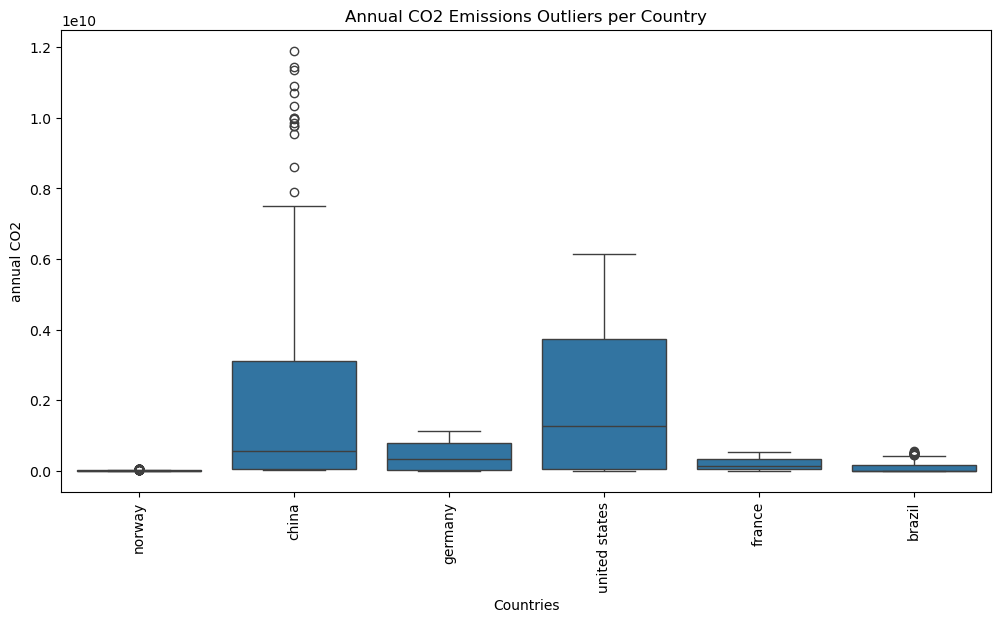

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.boxplot(x="Countries", y="annual CO2", data=df_total)
plt.xticks(rotation=90)
plt.title("Annual CO2 Emissions Outliers per Country")
plt.show()


Exploratory Data Analysis

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Make a clean copy
df_co2 = df_total.copy()

# Ensure year is numeric
df_co2["year"] = pd.to_numeric(df_co2["year"], errors="coerce")
df_co2 = df_co2.dropna(subset=["year"])
df_co2["year"] = df_co2["year"].astype(int)

# Clean country names
df_co2["Countries"] = (
    df_co2["Countries"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Rename CO2 column for convenience
df_co2 = df_co2.rename(columns={"annual CO2": "annual_co2"})


In [13]:
# Remove rows without population
df_pc = df_total.dropna(subset=["population"]).copy()

# Ensure year is numeric
df_pc["year"] = pd.to_numeric(df_pc["year"], errors="coerce")
df_pc = df_pc.dropna(subset=["year"])
df_pc["year"] = df_pc["year"].astype(int)

# Restrict to years with reliable population data
df_pc = df_pc[df_pc["year"] >= 1950]

# Clean country names (CRITICAL)
df_pc["Countries"] = (
    df_pc["Countries"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Rename CO2 column
df_pc = df_pc.rename(columns={"annual CO2": "annual_co2"})




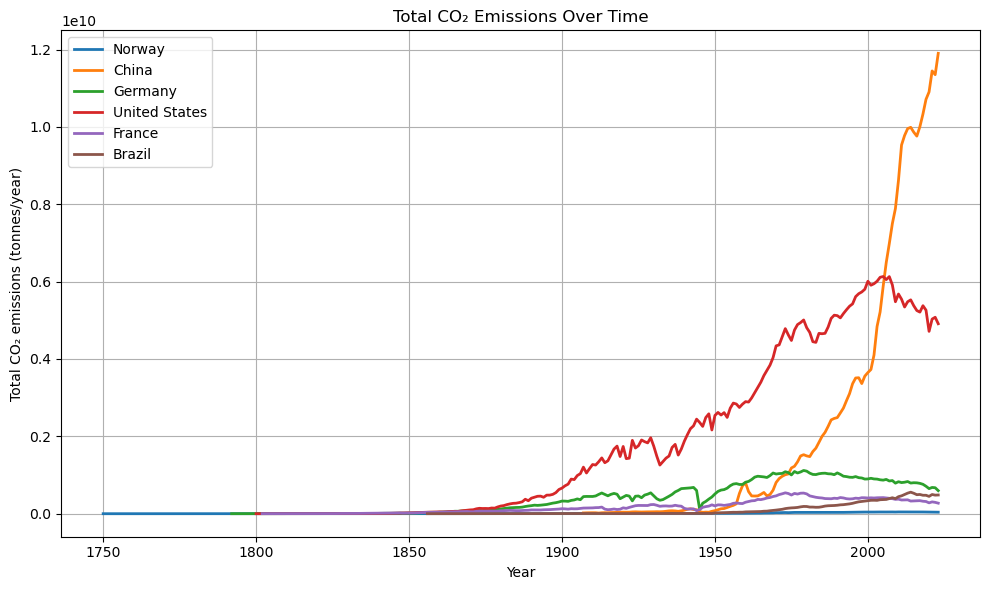

In [14]:
countries_to_plot = [
    "norway", "china", "germany",
    "united states", "france", "brazil"
]

plt.figure(figsize=(10, 6))

for country in countries_to_plot:
    subset = df_co2[df_co2["Countries"] == country]
    if subset.empty:
        print(f"⚠️ No data for {country}")
        continue

    plt.plot(
        subset["year"],
        subset["annual_co2"],
        label=country.title(),
        linewidth=2
    )

plt.xlabel("Year")
plt.ylabel("Total CO₂ emissions (tonnes/year)")
plt.title("Total CO₂ Emissions Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:
# annual_co2 is already in tonnes
df_pc["co2_per_capita"] = df_pc["annual_co2"] / df_pc["population"]



In [16]:
print(df_pc[["Countries", "year", "co2_per_capita"]].describe())



              year  co2_per_capita
count   444.000000      444.000000
mean   1986.500000        8.067323
std      21.384104        6.019178
min    1950.000000        0.144906
25%    1968.000000        2.407255
50%    1986.500000        7.396605
75%    2005.000000       11.271939
max    2023.000000       22.257155


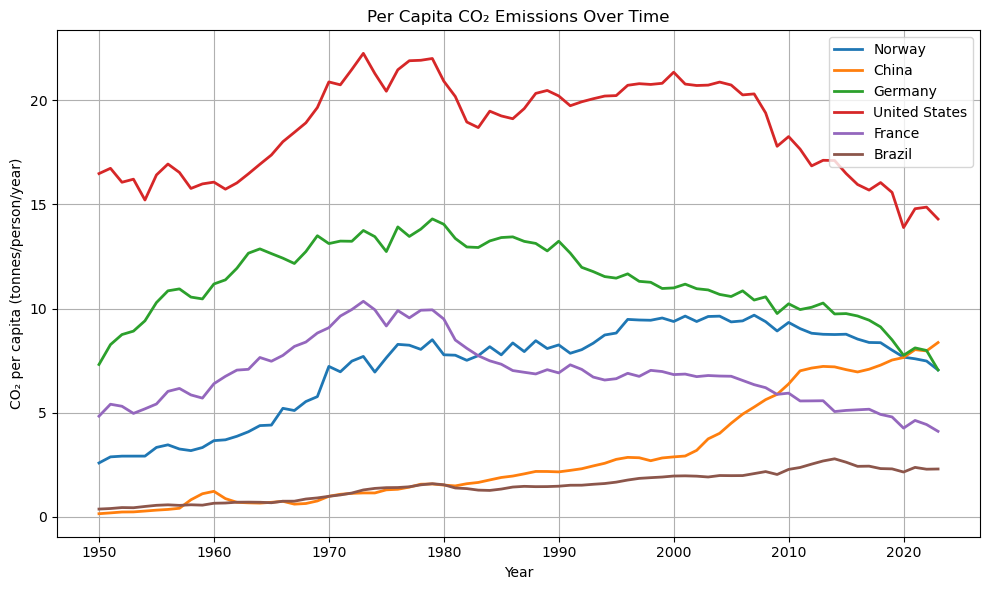

In [17]:
countries_to_plot = [
    "norway", "china", "germany",
    "united states", "france", "brazil"
]

plt.figure(figsize=(10, 6))

for country in countries_to_plot:
    subset = df_pc[df_pc["Countries"] == country]
    if subset.empty:
        print(f"⚠️ No data for {country}")
        continue

    plt.plot(
        subset["year"],
        subset["co2_per_capita"],
        label=country.title(),
        linewidth=2
    )

plt.xlabel("Year")
plt.ylabel("CO₂ per capita (tonnes/person/year)")
plt.title("Per Capita CO₂ Emissions Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


<Figure size 900x600 with 0 Axes>

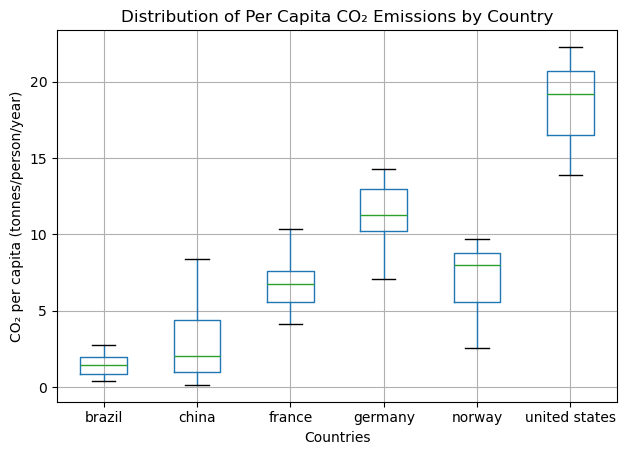

In [18]:
plt.figure(figsize=(9, 6))

df_pc.boxplot(
    column="co2_per_capita",
    by="Countries",
    grid=True
)

plt.ylabel("CO₂ per capita (tonnes/person/year)")
plt.title("Distribution of Per Capita CO₂ Emissions by Country")
plt.suptitle("")
plt.tight_layout()
plt.show()


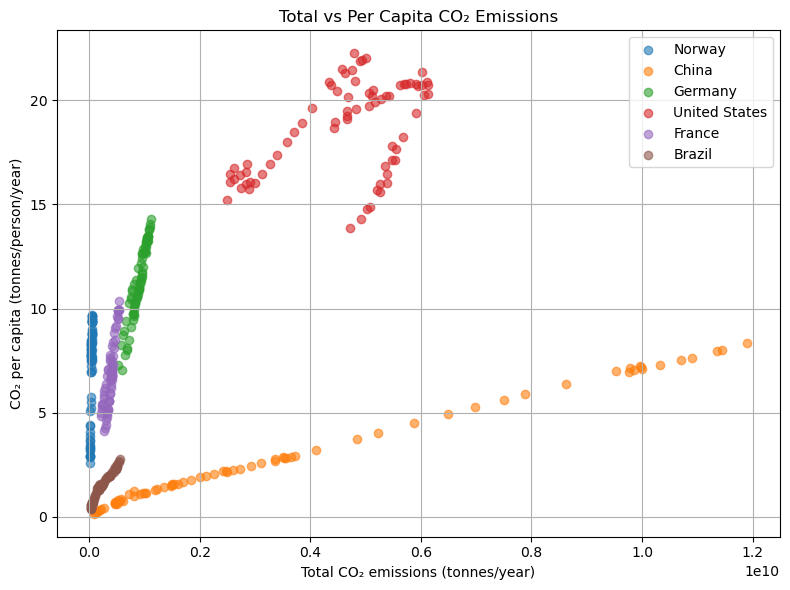

In [19]:
plt.figure(figsize=(8, 6))

for country in countries_to_plot:
    subset = df_pc[df_pc["Countries"] == country]
    plt.scatter(
        subset["annual_co2"],
        subset["co2_per_capita"],
        label=country.title(),
        alpha=0.6
    )

plt.xlabel("Total CO₂ emissions (tonnes/year)")
plt.ylabel("CO₂ per capita (tonnes/person/year)")
plt.title("Total vs Per Capita CO₂ Emissions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Statistically and Comparitive analysis

CO2 per GDP

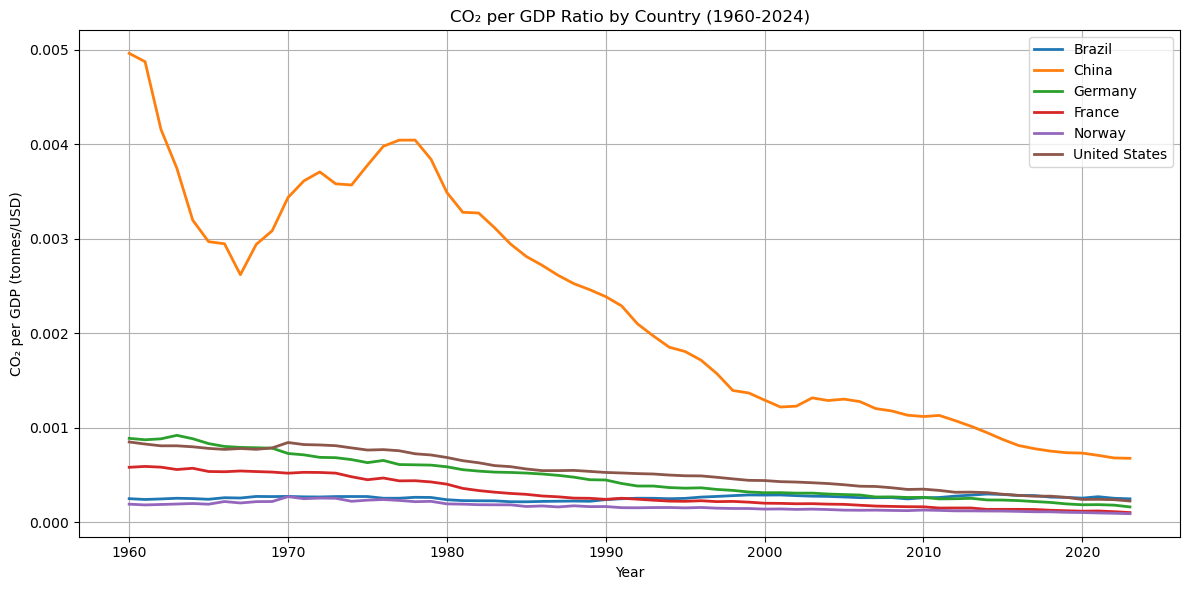

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Read CO2 data from first sheet of Excel file
df_co2_raw = pd.read_excel("dataset_project_total.xlsx", sheet_name=0)

# Read GDP data from the second sheet of Excel file
df_gdp = pd.read_excel("dataset_project_total.xlsx", sheet_name=1)

# Clean column names
df_co2_raw.columns = df_co2_raw.columns.str.strip()
df_gdp.columns = df_gdp.columns.str.strip()

# Prepare CO2 data
co2_sub = df_co2_raw[["Countries", "year", "annual CO2"]].copy()
co2_sub.columns = ["country", "year", "co2"]
co2_sub["country"] = co2_sub["country"].str.strip().str.lower()
co2_sub["year"] = pd.to_numeric(co2_sub["year"], errors="coerce")

# Prepare GDP data - adjust column names based on your actual file
gdp_sub = df_gdp[["Country Name", "year", "gdp"]].copy()
gdp_sub.columns = ["country", "year", "gdp"]
gdp_sub["country"] = gdp_sub["country"].str.strip().str.lower()
gdp_sub["year"] = pd.to_numeric(gdp_sub["year"], errors="coerce")

# Filter to 1960-2024
gdp_sub = gdp_sub[(gdp_sub["year"] >= 1960) & (gdp_sub["year"] <= 2024)]
co2_sub = co2_sub[(co2_sub["year"] >= 1960) & (co2_sub["year"] <= 2024)]

# Merge datasets
df_merged = pd.merge(co2_sub, gdp_sub, on=["country", "year"], how="inner")

# Calculate CO2 per GDP
df_merged["co2_per_gdp"] = df_merged["co2"] / df_merged["gdp"]

# Select countries to plot
countries_six = ["brazil", "china", "germany", "france", "norway", "united states"]

# Plot CO2 per GDP
plt.figure(figsize=(12, 6))
for country in countries_six:
    subset = df_merged[df_merged["country"] == country]
    if not subset.empty:
        plt.plot(subset["year"], subset["co2_per_gdp"], label=country.title(), linewidth=2)

plt.xlabel("Year")
plt.ylabel("CO₂ per GDP (tonnes/USD)")
plt.title("CO₂ per GDP Ratio by Country (1960-2024)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

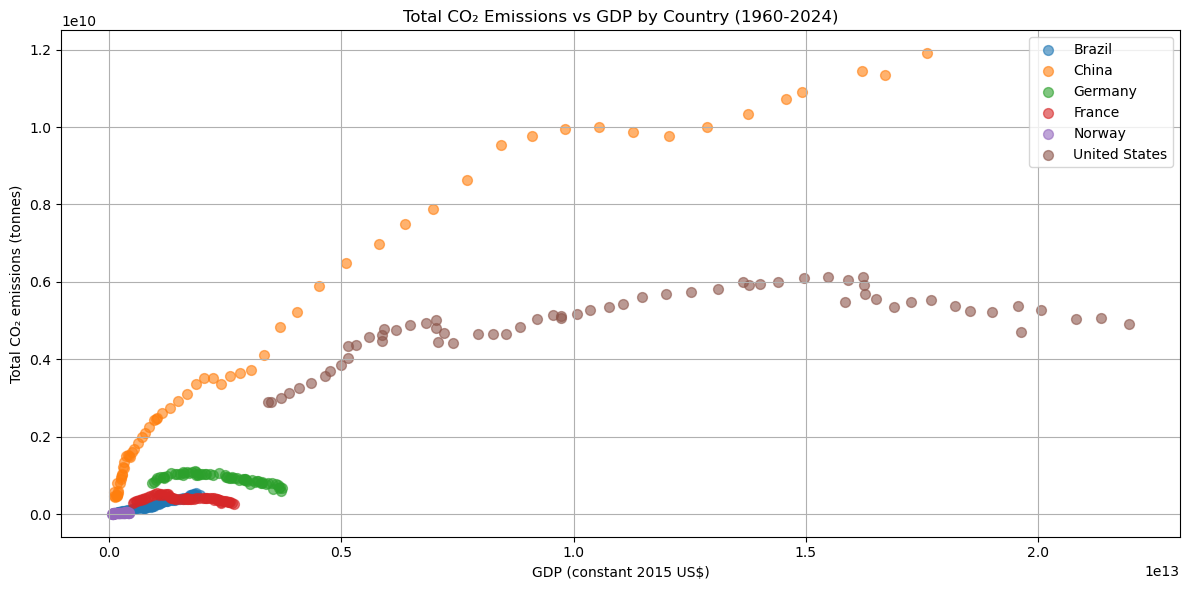

In [21]:
# Plot Total CO2 Emissions vs GDP
plt.figure(figsize=(12, 6))

for country in countries_six:
    subset = df_merged[df_merged["country"] == country]
    if not subset.empty:
        plt.scatter(subset["gdp"], subset["co2"], label=country.title(), alpha=0.6, s=50)

plt.xlabel("GDP (constant 2015 US$)")
plt.ylabel("Total CO₂ emissions (tonnes)")
plt.title("Total CO₂ Emissions vs GDP by Country (1960-2024)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Time Series 

Noise Filtering

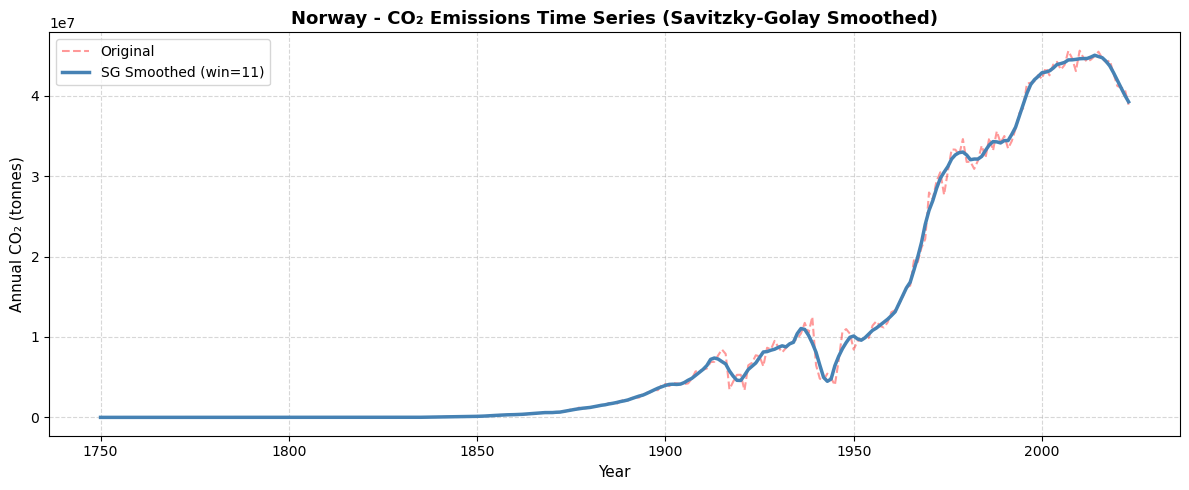

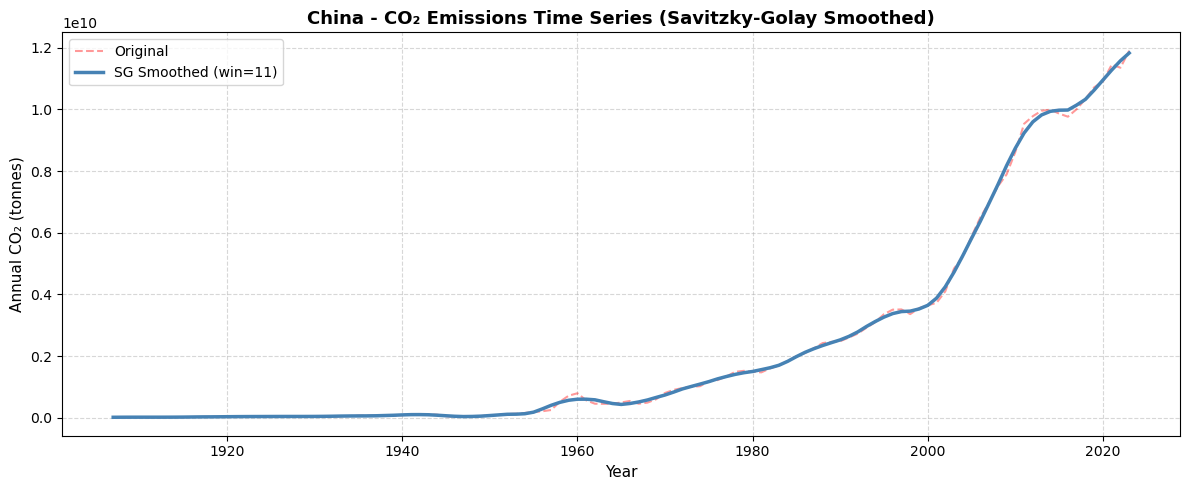

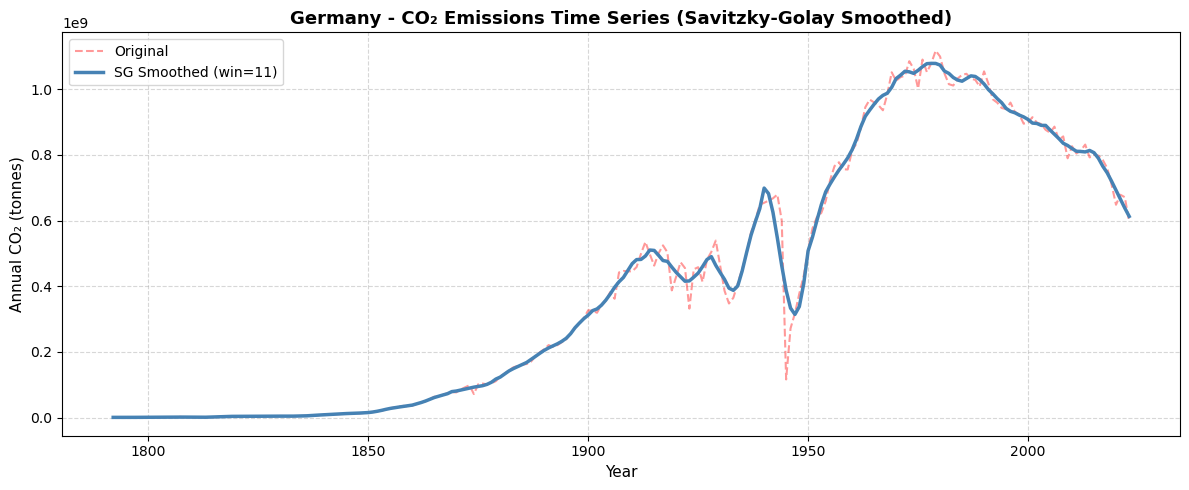

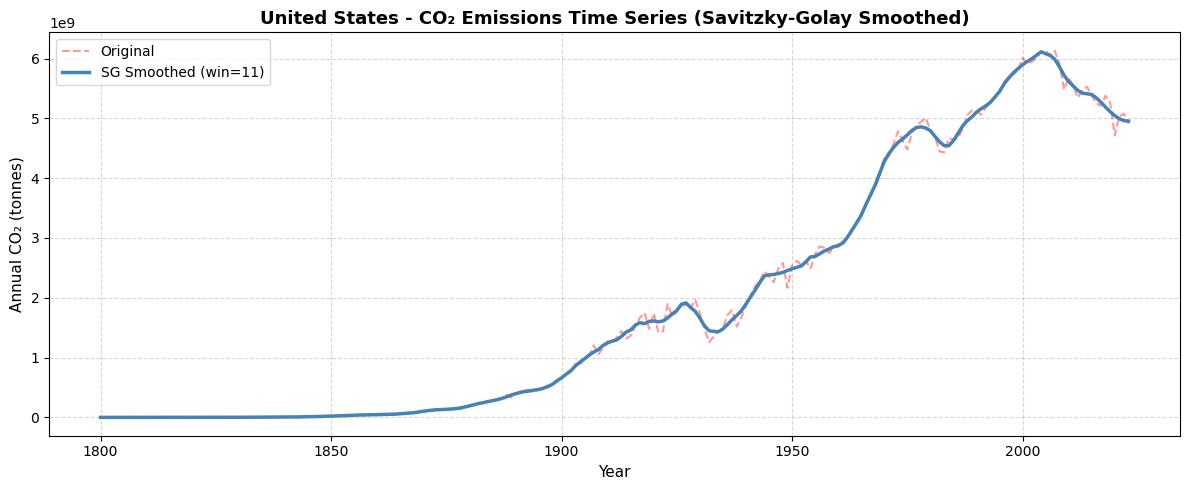

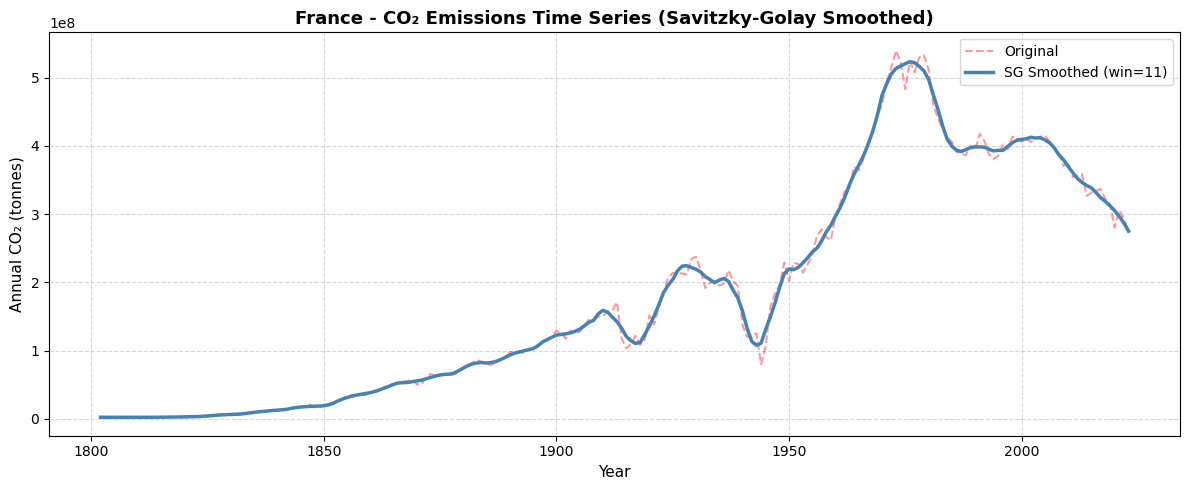

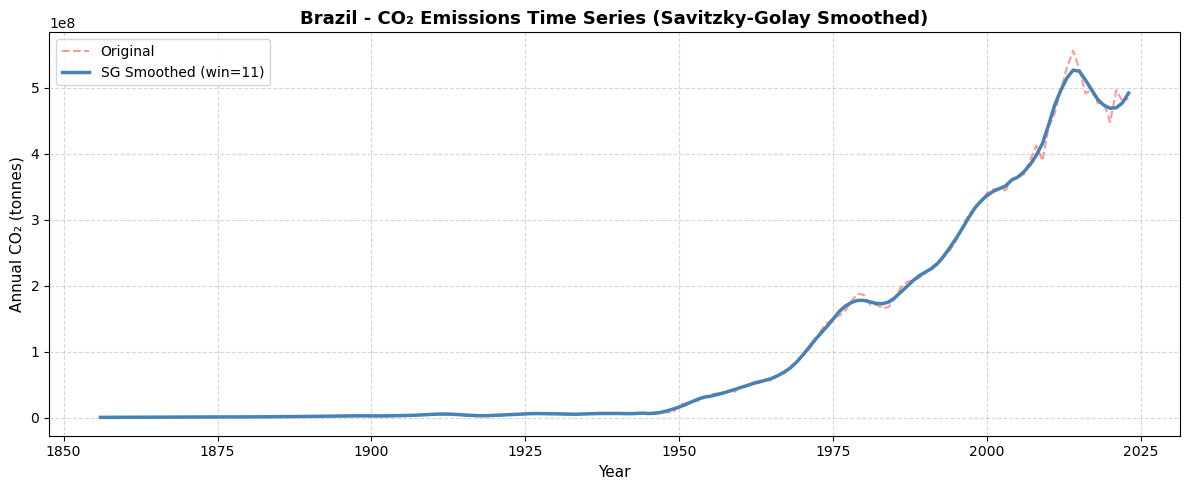

In [22]:
# Time series analysis for all countries with Savitzky-Golay smoothing - Separate figures
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt

# Get all unique countries
countries_list = df_total['Countries'].unique()

# Process each country and create separate figure for each
for country in countries_list:
    country_data = df_total[df_total['Countries'] == country].sort_values('year')
    
    if len(country_data) < 3:
        print(f"⚠️ Insufficient data for {country.title()}")
        continue
    
    years = country_data['year'].values
    emissions = country_data['annual CO2'].values
    
    # Adjust window length to be smaller than data size and odd number
    window_length = min(11, len(emissions) if len(emissions) % 2 == 1 else len(emissions) - 1)
    if window_length < 3:
        window_length = 3
    
    # Apply Savitzky-Golay filter
    smoothed = savgol_filter(emissions, window_length=window_length, polyorder=3)
    
    # Create separate figure for each country
    plt.figure(figsize=(12, 5))
    plt.plot(years, emissions, label='Original', linestyle='--', linewidth=1.5, alpha=0.4, color='red')
    plt.plot(years, smoothed, label=f'SG Smoothed (win={window_length})', linewidth=2.5, color='steelblue')
    
    plt.xlabel('Year', fontsize=11)
    plt.ylabel('Annual CO₂ (tonnes)', fontsize=11)
    plt.title(f'{country.title()} - CO₂ Emissions Time Series (Savitzky-Golay Smoothed)', fontsize=13, fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

Autocorrelation

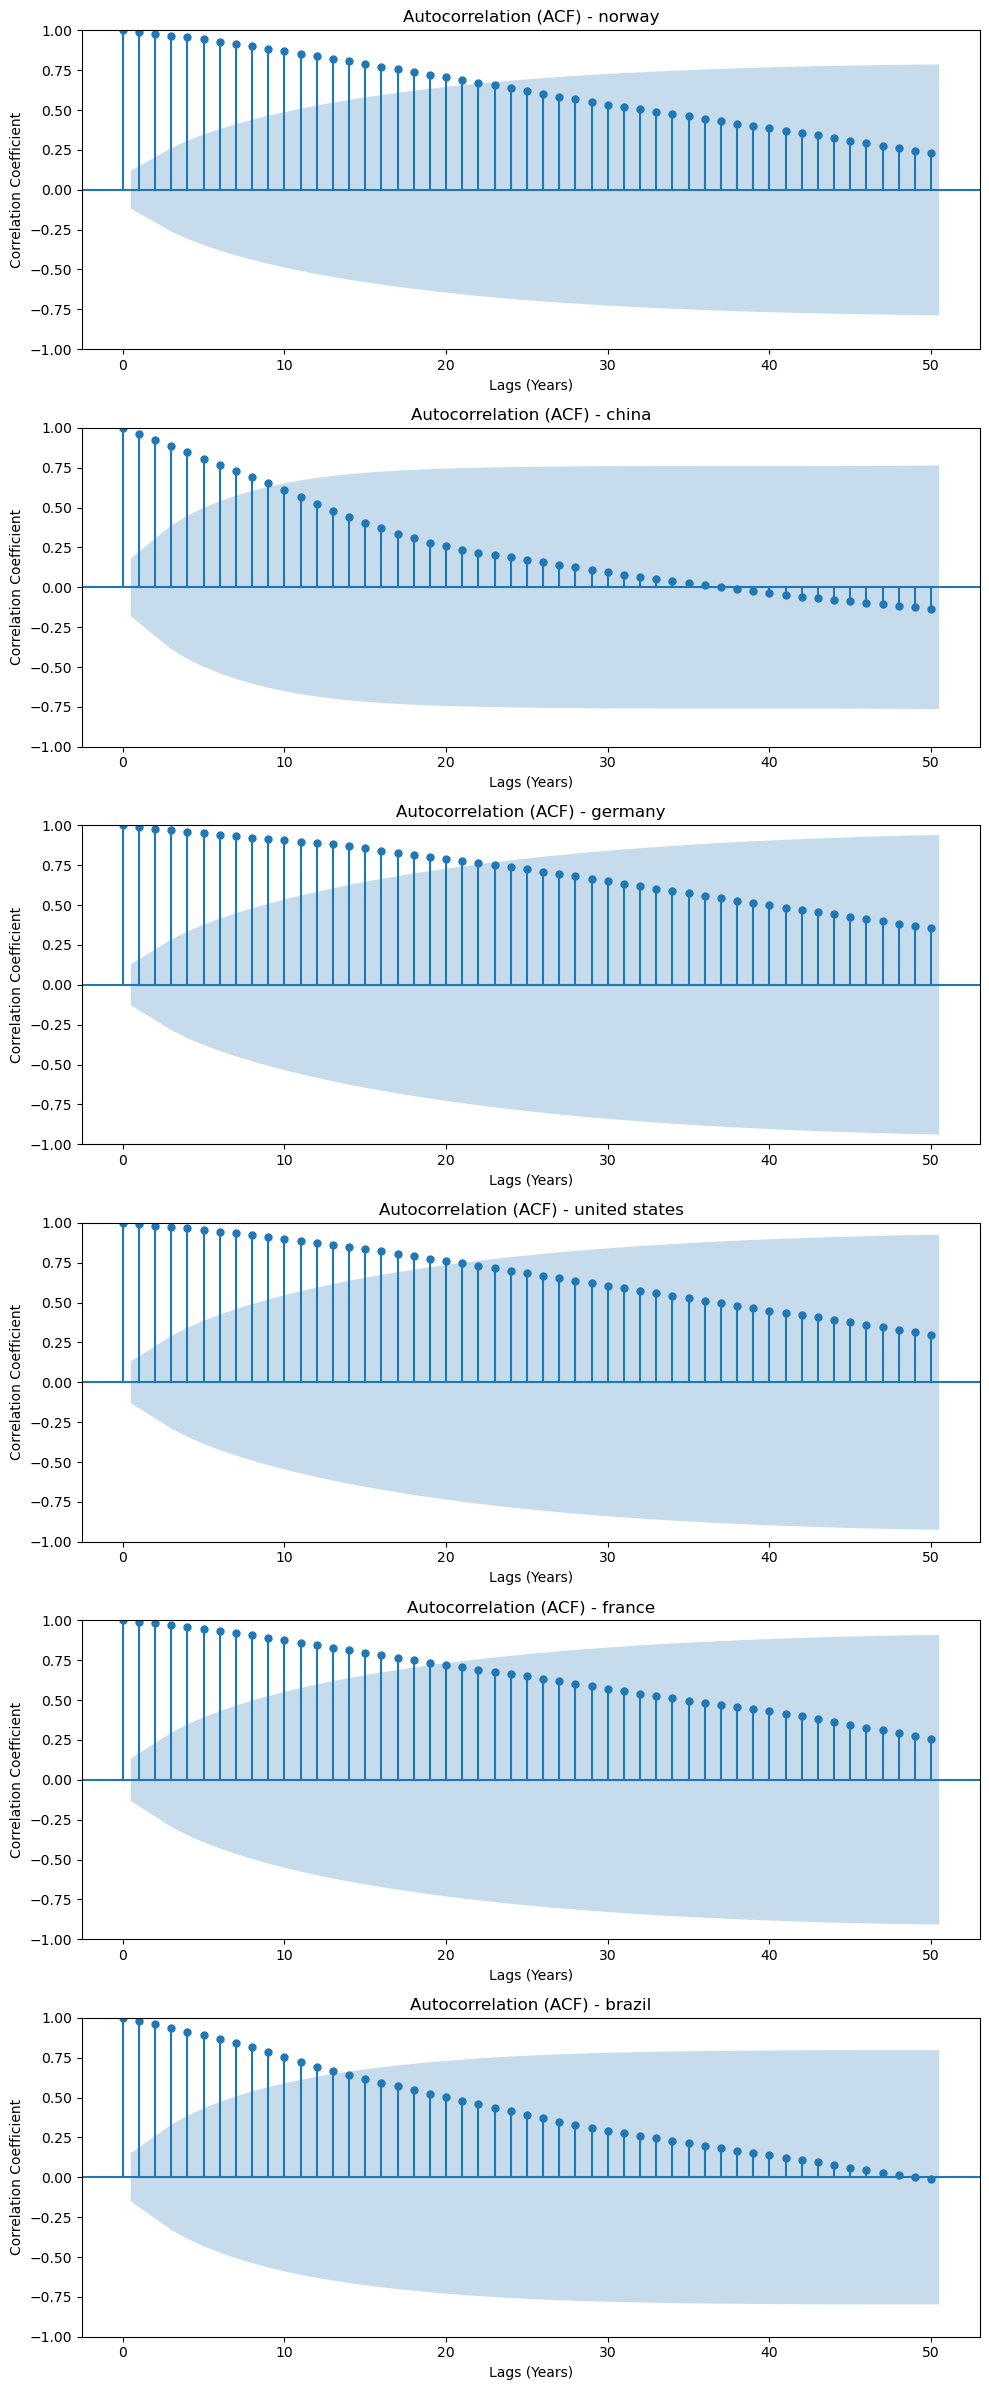

In [23]:
#autocorrelation: measures how current values depend on past values, If emissions are high this year, they are likely high next year → positive autocorrelation
from sklearn import preprocessing
from statsmodels.graphics.tsaplots import plot_acf

countries = df_total['Countries'].unique()
# Create a multi-plot figure for all countries
fig, axes = plt.subplots(len(countries), 1, figsize=(10, 4 * len(countries)))

for i, country in enumerate(countries):
    # Filter and sort by year
    subset = df_total[df_total['Countries'] == country].sort_values('year')
    series = subset['annual CO2'].dropna()
    
    # Plot ACF (up to 50 years of lag)
    plot_acf(series, ax=axes[i], lags=50, title=f'Autocorrelation (ACF) - {country}')
    axes[i].set_xlabel('Lags (Years)')
    axes[i].set_ylabel('Correlation Coefficient')

plt.tight_layout()
plt.savefig('autocorrelation_total_emissions.png')
plt.show()

Decomposition

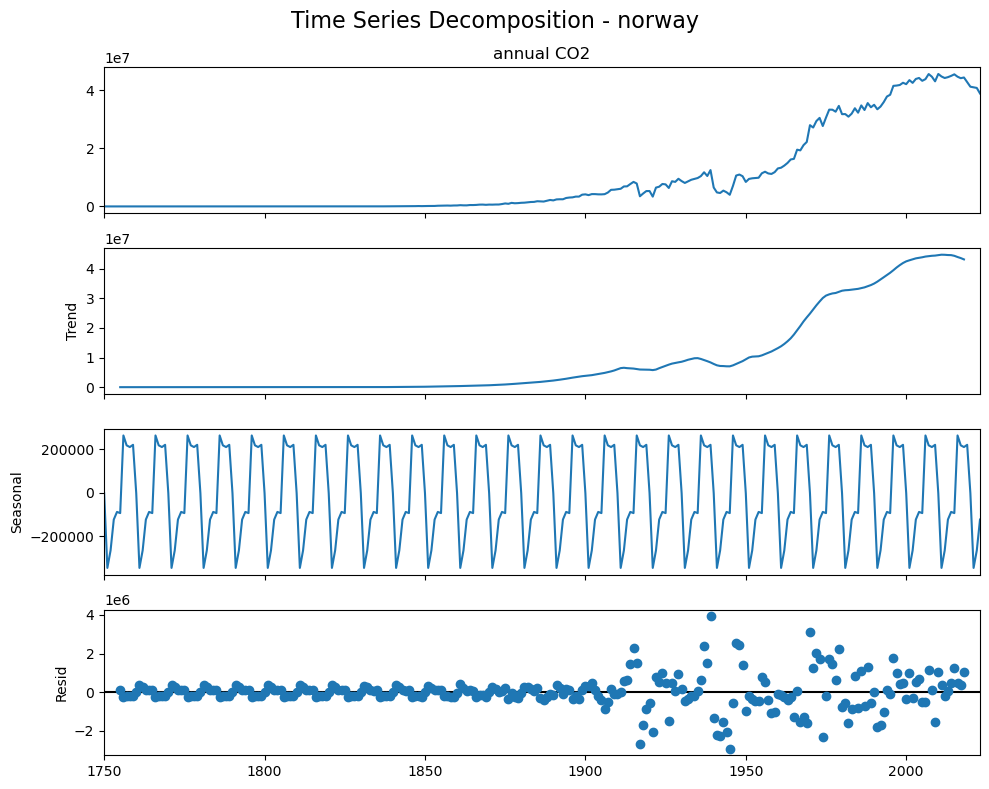

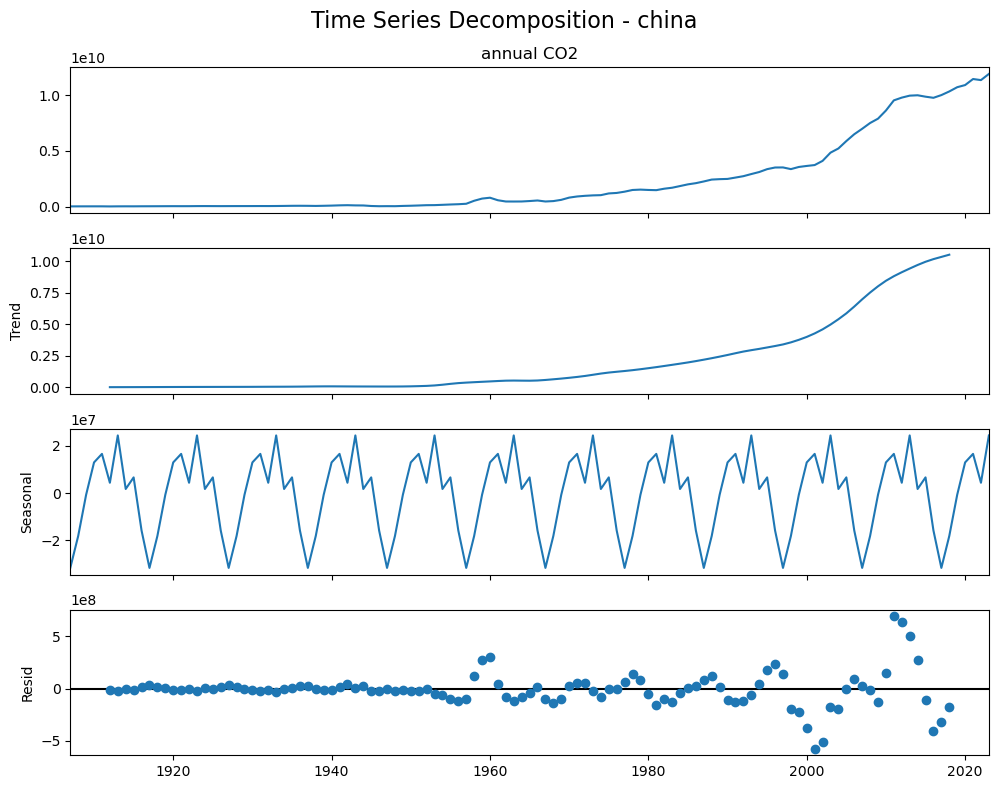

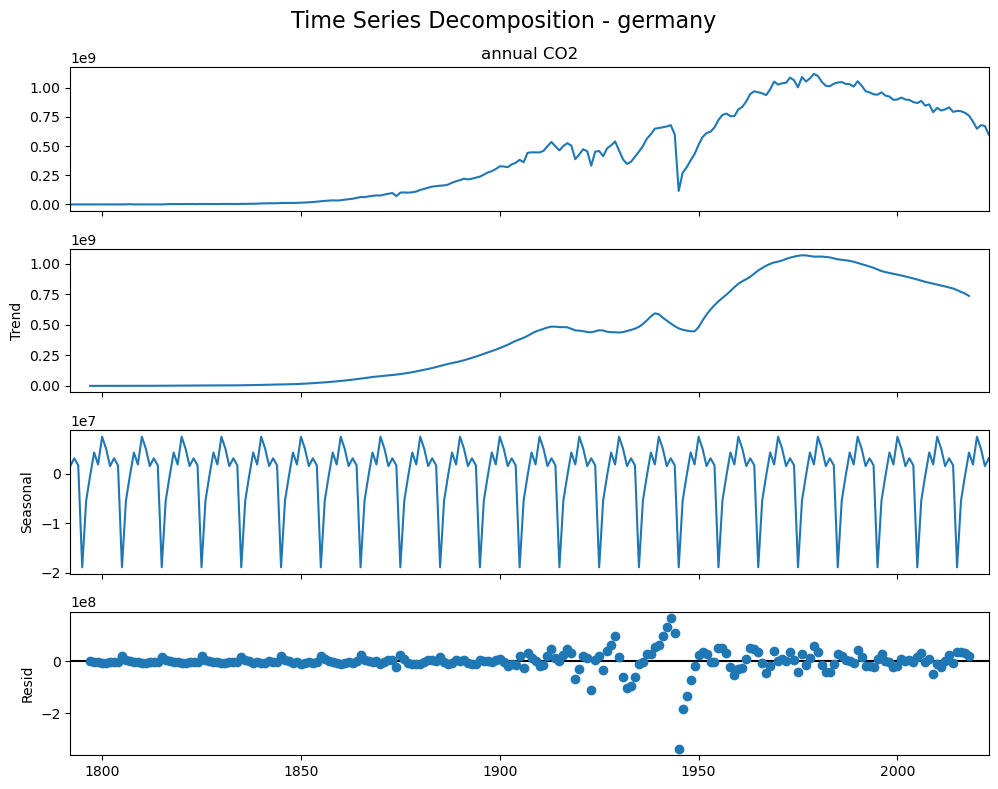

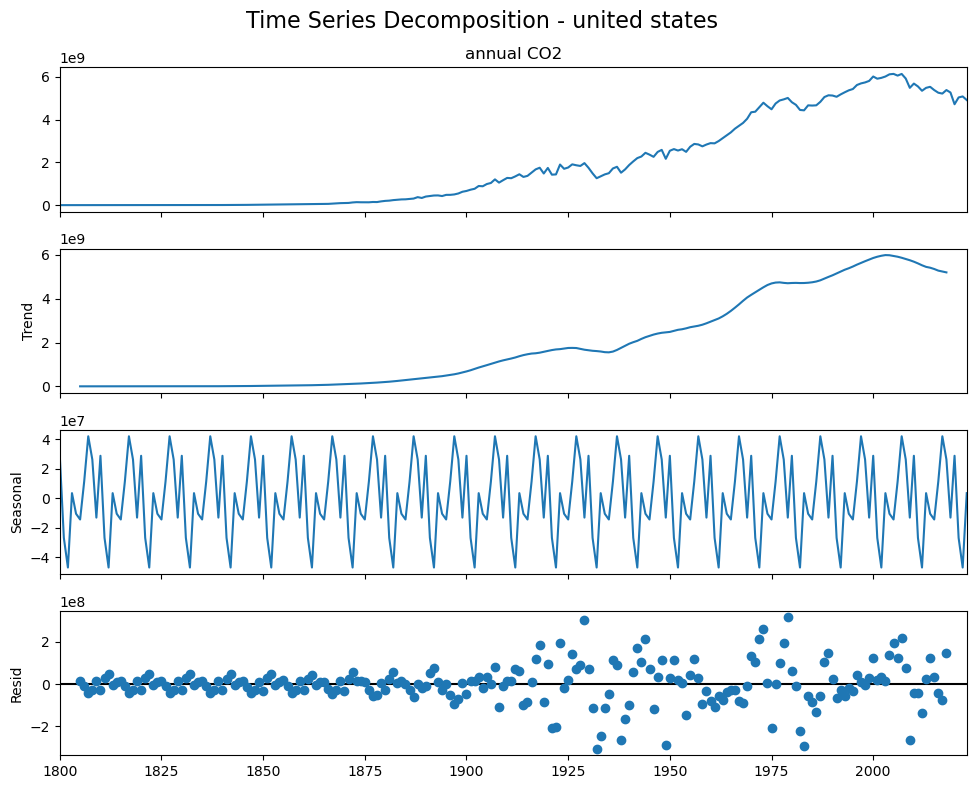

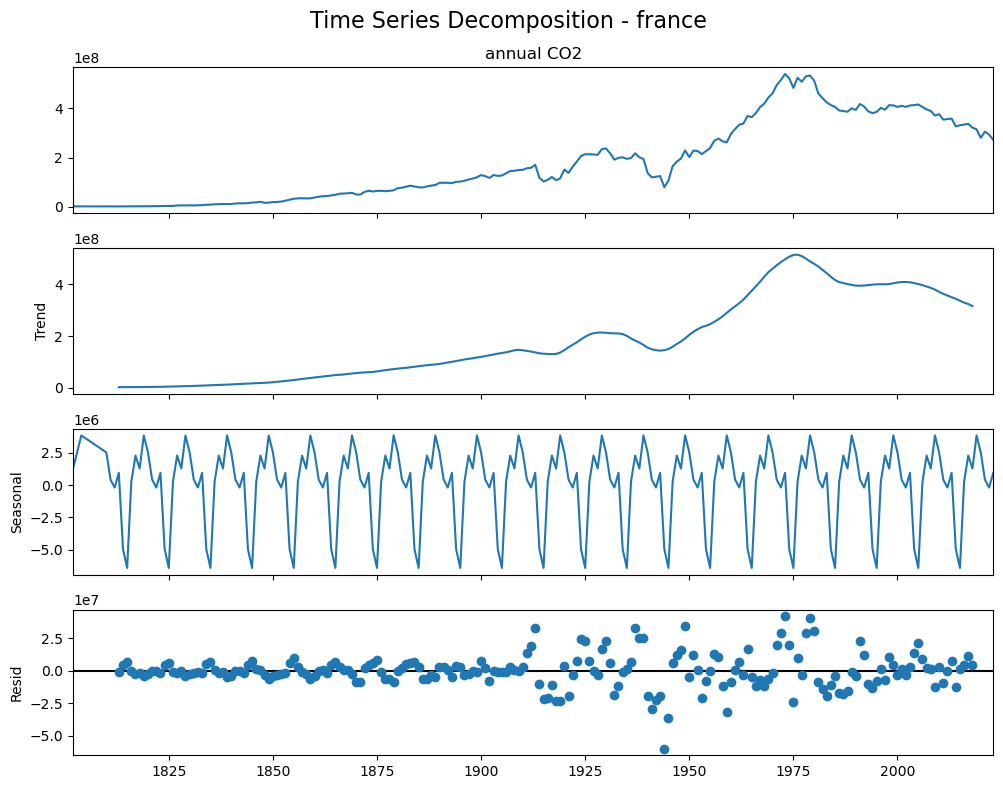

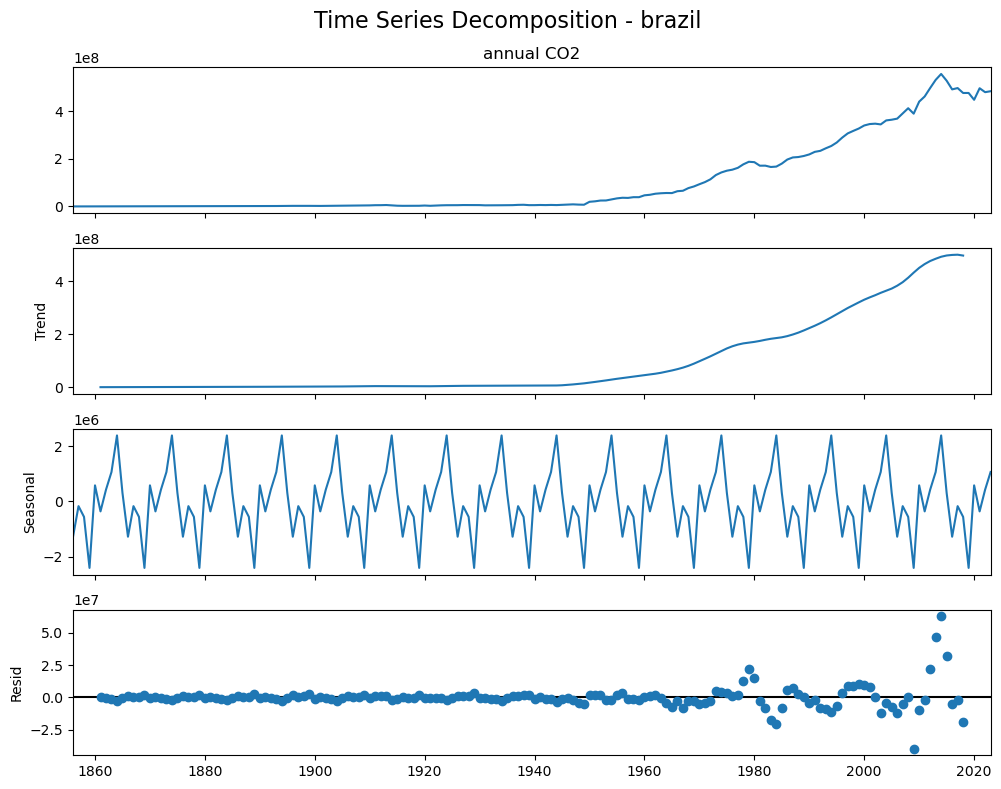

In [24]:
#decomposition
from statsmodels.tsa.seasonal import seasonal_decompose
countries = df_total['Countries'].unique()
for country in countries:
    subset = df_total[df_total['Countries'] == country].sort_values('year')
    series = subset.set_index('year')['annual CO2'].dropna()
    
    # Decompose the time series
    decomposition = seasonal_decompose(series, model='additive', period=10)
    
    # Plot the decomposition
    fig = decomposition.plot()
    fig.set_size_inches(10, 8)
    fig.suptitle(f'Time Series Decomposition - {country}', fontsize=16)
    plt.tight_layout()
    plt.savefig(f'time_series_decomposition_{country}.png')
    plt.show()

Forecasting with ARIMA

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


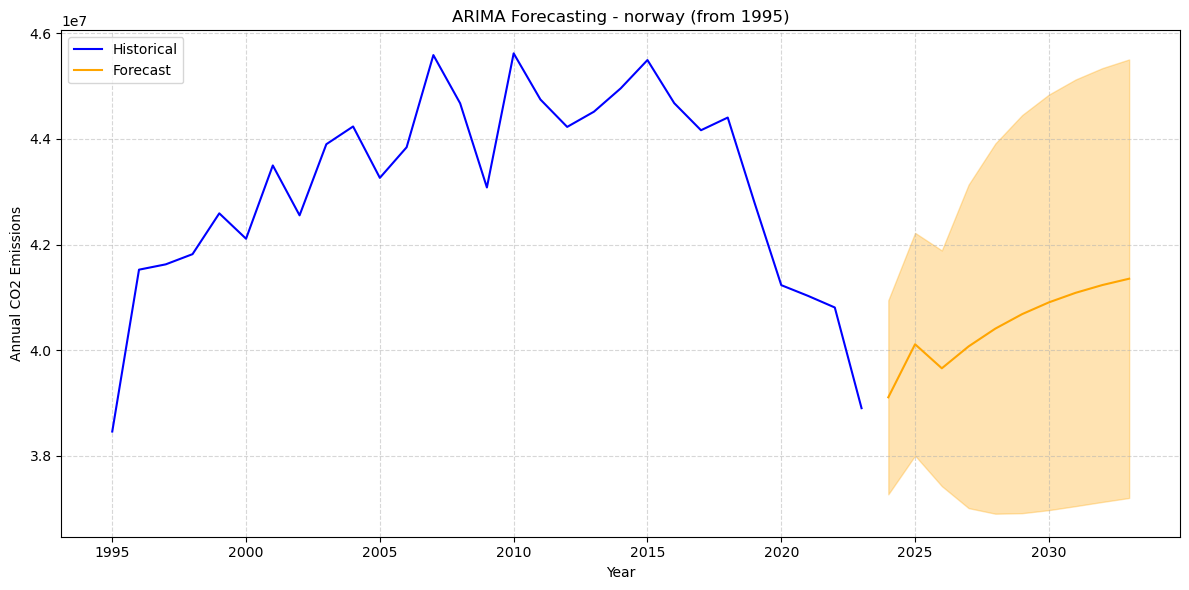

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


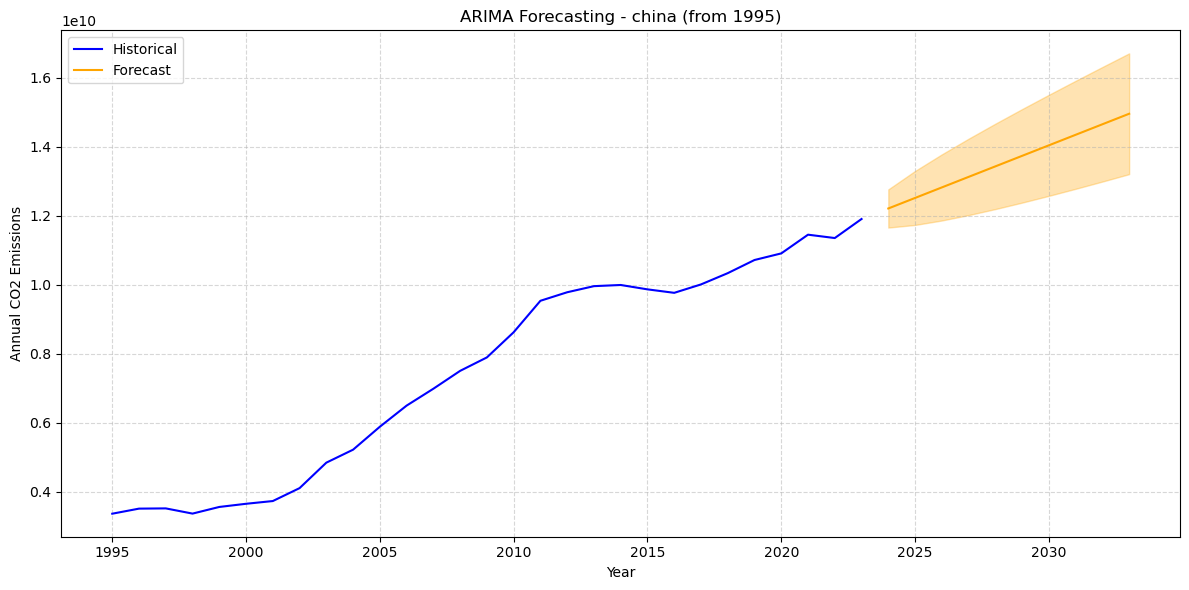

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


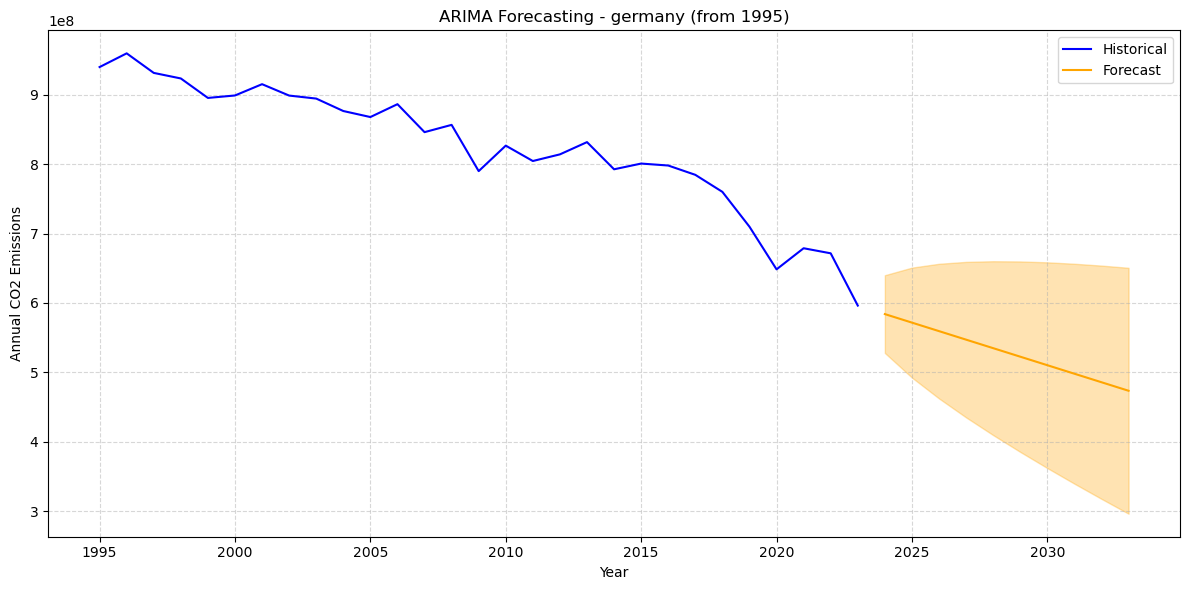

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


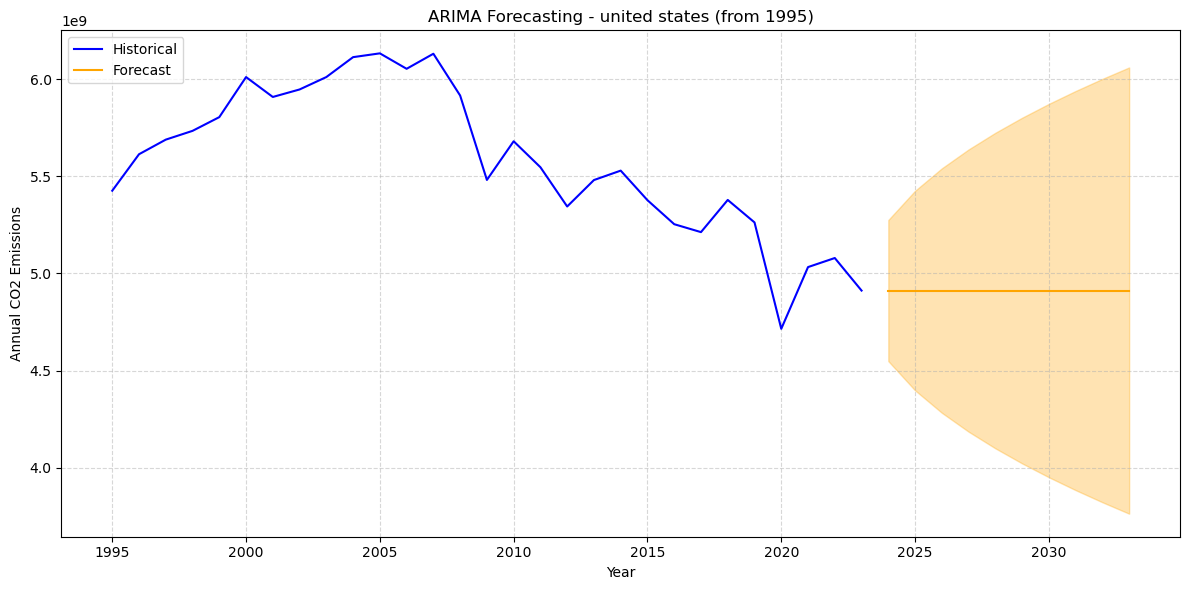

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


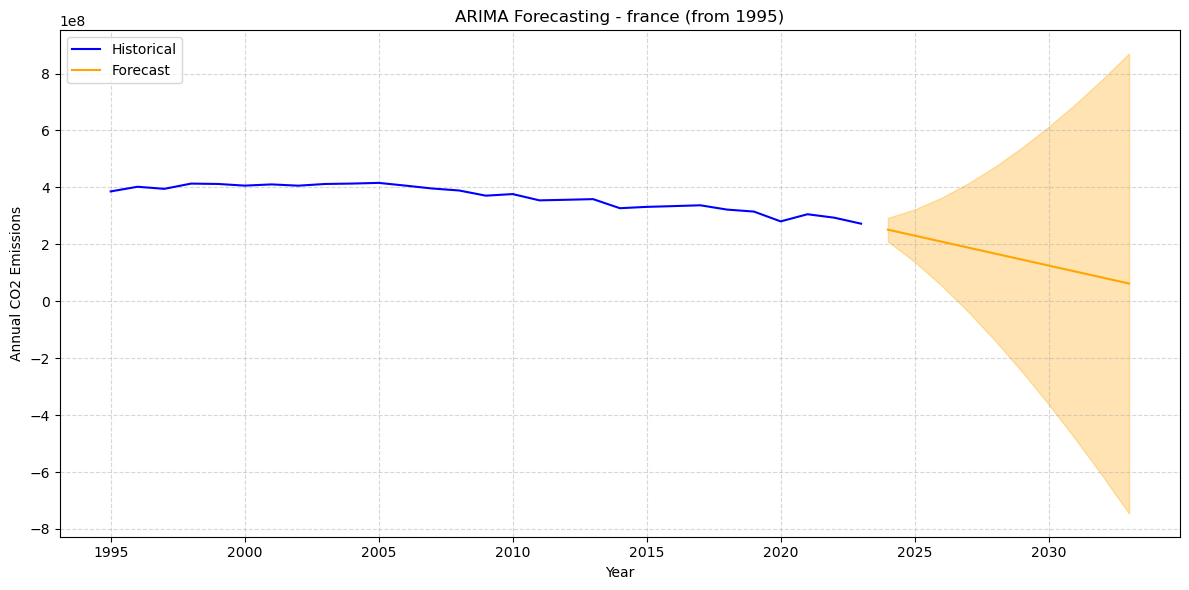

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


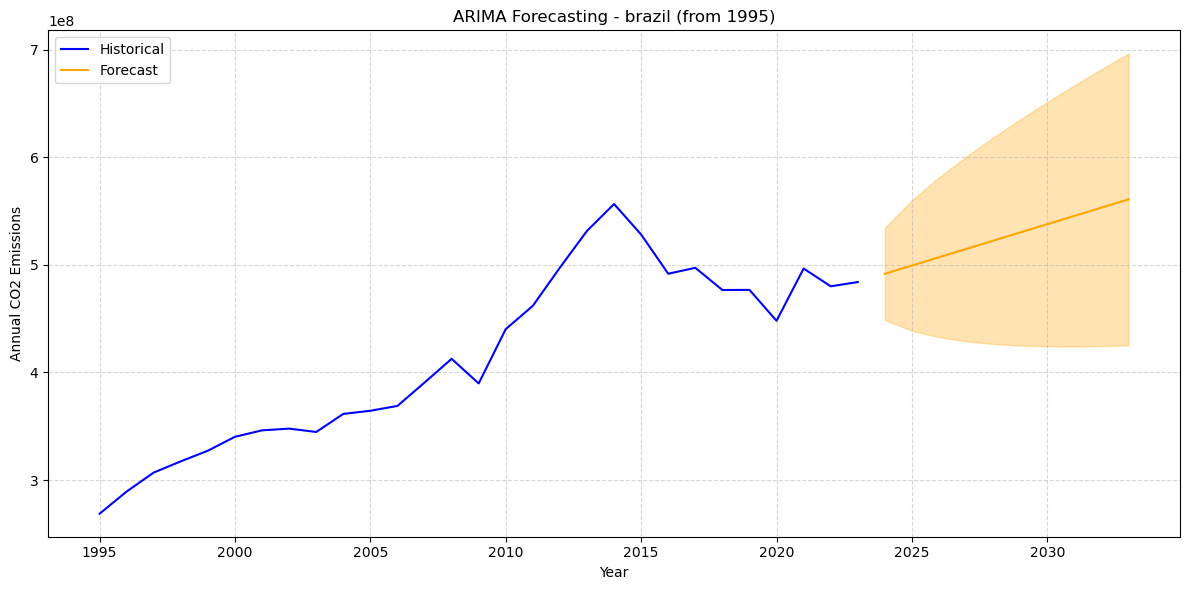

In [25]:
#forecasting with ARIMA
import pmdarima as pm
countries = df_total['Countries'].unique()
for country in countries:
    subset = df_total[df_total['Countries'] == country].sort_values('year')
    series = subset.set_index('year')['annual CO2'].dropna()
    
    # Filter data from 1995 onwards
    series = series[series.index >= 1995]
    
    # Fit ARIMA model
    model = pm.auto_arima(series, seasonal=False, stepwise=True, suppress_warnings=True)
    
    # Forecast the next 10 years
    n_periods = 10
    forecast, conf_int = model.predict(n_periods=n_periods, return_conf_int=True)
    
    # Create forecast index
    forecast_index = range(series.index[-1] + 1, series.index[-1] + n_periods + 1)
    
    # Plot the results
    plt.figure(figsize=(12, 6))
    plt.plot(series.index, series, label='Historical', color='blue')
    plt.plot(forecast_index, forecast, label='Forecast', color='orange')
    plt.fill_between(forecast_index, conf_int[:, 0], conf_int[:, 1], color='orange', alpha=0.3)
    
    plt.title(f'ARIMA Forecasting - {country} (from 1995)')
    plt.xlabel('Year')
    plt.ylabel('Annual CO2 Emissions')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(f'arima_forecast_{country}_1995.png')
    plt.show()

Backtesting

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


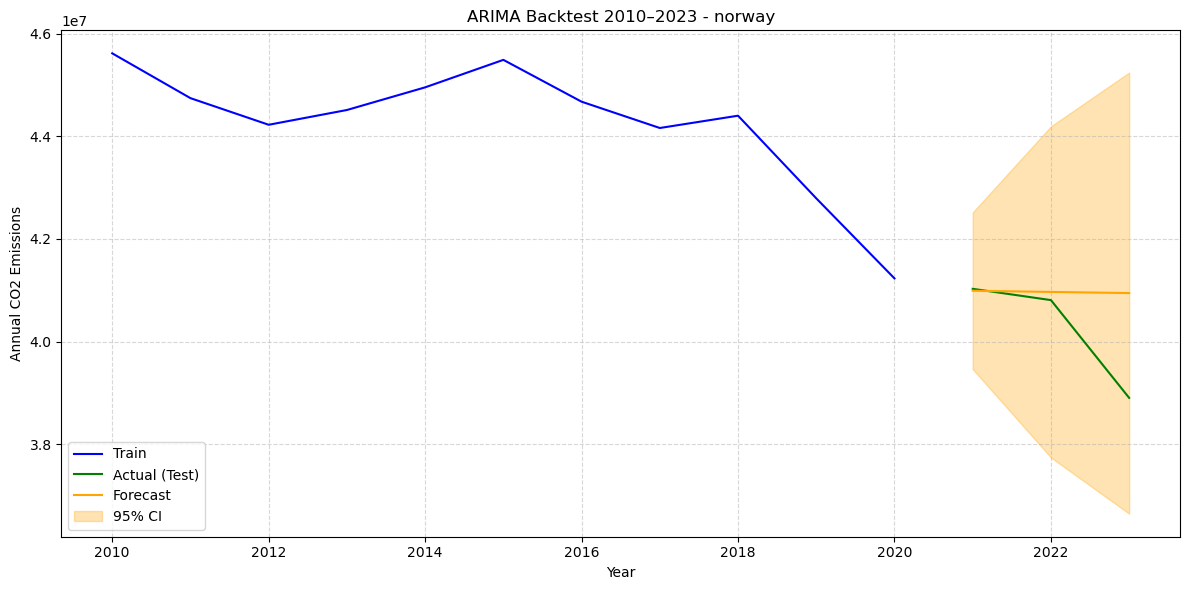

norway - MAE: 747017.15, RMSE: 1183827.62


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


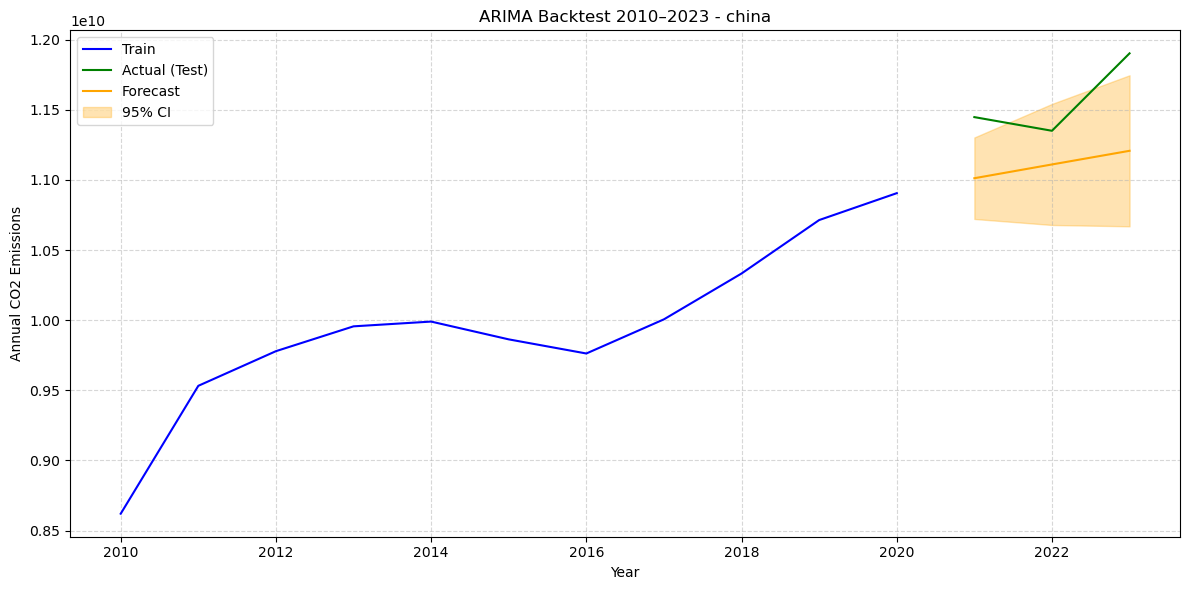

china - MAE: 456823386.78, RMSE: 493313921.57


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


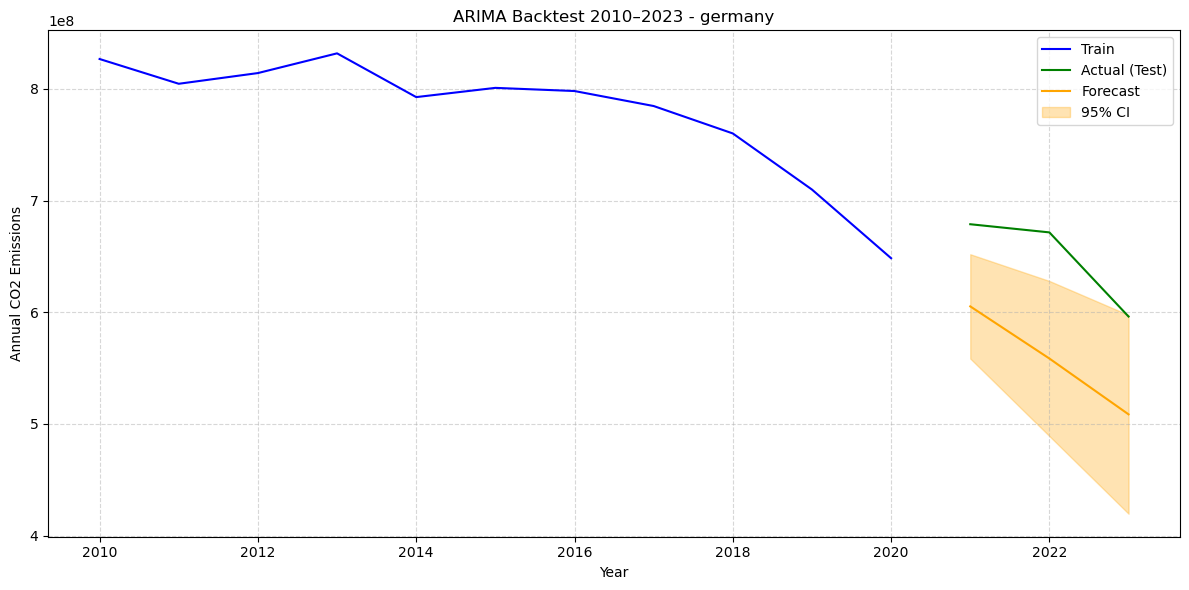

germany - MAE: 91335533.01, RMSE: 92777927.28


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


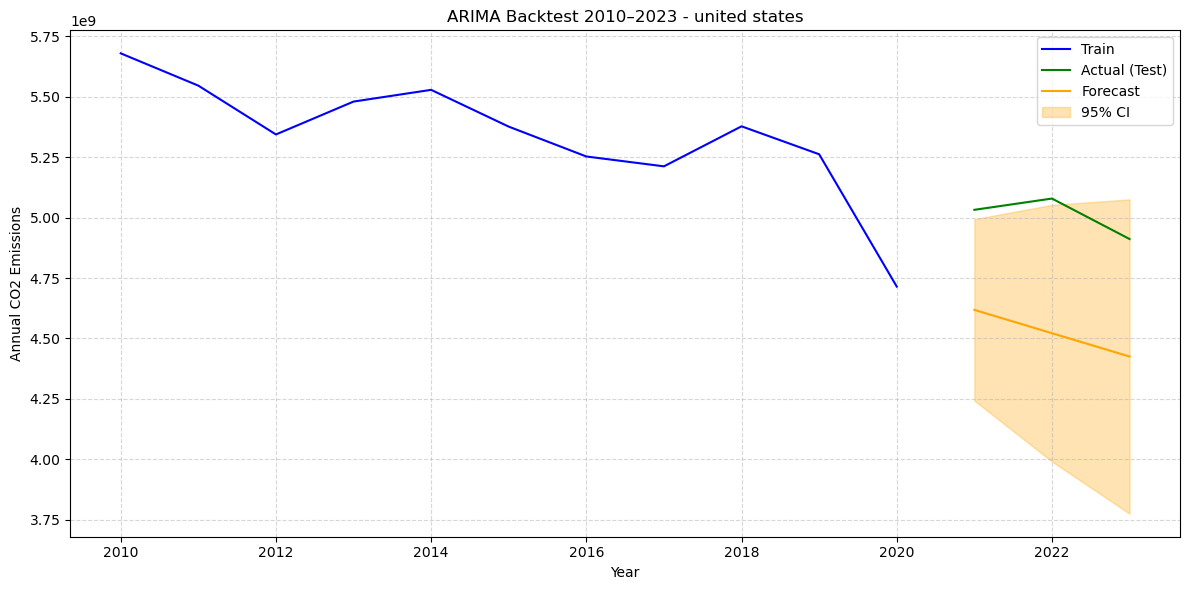

united states - MAE: 485881126.67, RMSE: 489383971.20


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


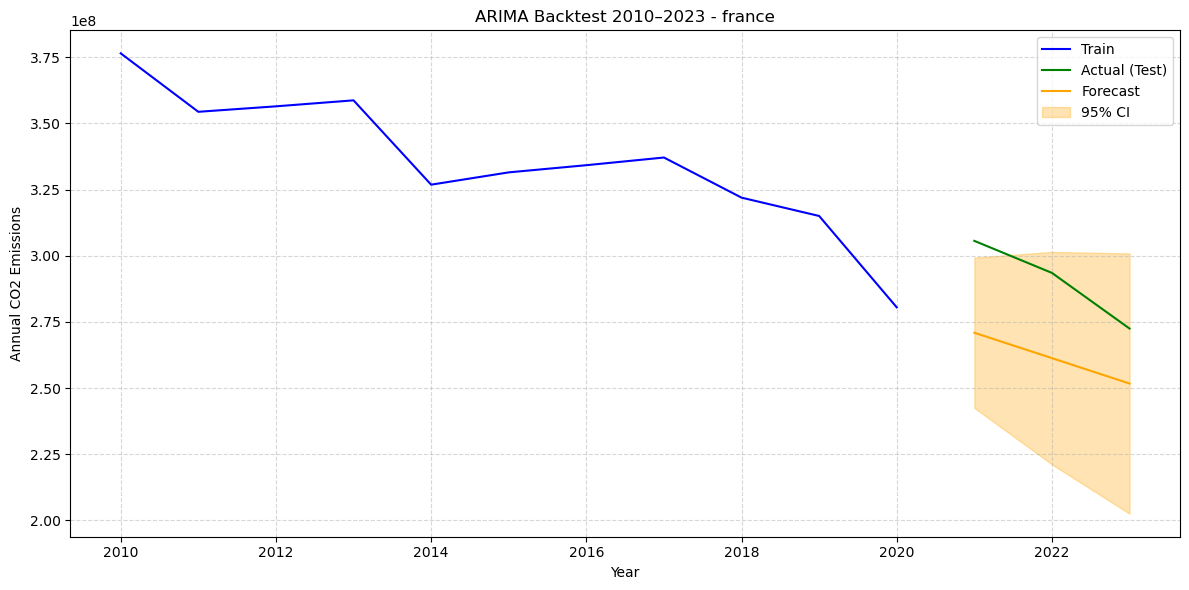

france - MAE: 29231649.33, RMSE: 29854440.66


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


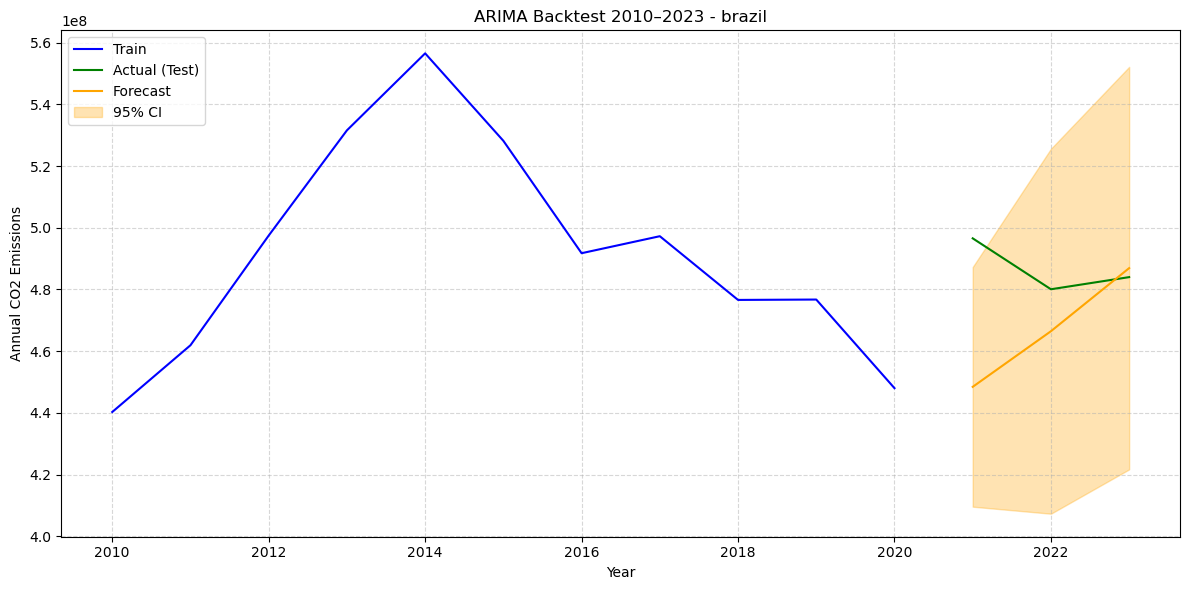

brazil - MAE: 21551487.80, RMSE: 28929227.78


In [26]:
import matplotlib.pyplot as plt
import pmdarima as pm

countries = df_total['Countries'].unique()

for country in countries:
    subset = df_total[df_total['Countries'] == country].sort_values('year')
    series = subset.set_index('year')['annual CO2'].dropna()

    # Use only years from 2010 onwards
    series = series[series.index >= 2010]

    # Define train and test (change 2020/2023 to match your dataset)
    train = series[series.index <= 2020]   # data used to fit the model
    test = series[series.index > 2020]     # data used for validation (e.g. 2021–2023)

    # Skip if not enough data
    if len(train) < 5 or len(test) == 0:
        print(f"Not enough data to backtest for {country}")
        continue

    # Fit ARIMA on the training part
    model = pm.auto_arima(
        train,
        seasonal=False,
        stepwise=True,
        suppress_warnings=True
    )

    # Forecast exactly len(test) years ahead
    n_periods = len(test)
    forecast, conf_int = model.predict(n_periods=n_periods, return_conf_int=True)

    # Build forecast index to align with test years
    forecast_index = test.index

    # Plot: training, actual test, and forecast
    plt.figure(figsize=(12, 6))
    plt.plot(train.index, train, label='Train', color='blue')
    plt.plot(test.index, test, label='Actual (Test)', color='green')
    plt.plot(forecast_index, forecast, label='Forecast', color='orange')
    plt.fill_between(
        forecast_index,
        conf_int[:, 0],
        conf_int[:, 1],
        color='orange',
        alpha=0.3,
        label='95% CI'
    )

    plt.title(f'ARIMA Backtest 2010–2023 - {country}')
    plt.xlabel('Year')
    plt.ylabel('Annual CO2 Emissions')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Optional: print simple error metrics
    from sklearn.metrics import mean_absolute_error, mean_squared_error
    import numpy as np

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    print(f"{country} - MAE: {mae:.2f}, RMSE: {rmse:.2f}")


Backtesting 1990-2020

norway | MAE: 3262916.59, RMSE: 3746614.33


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


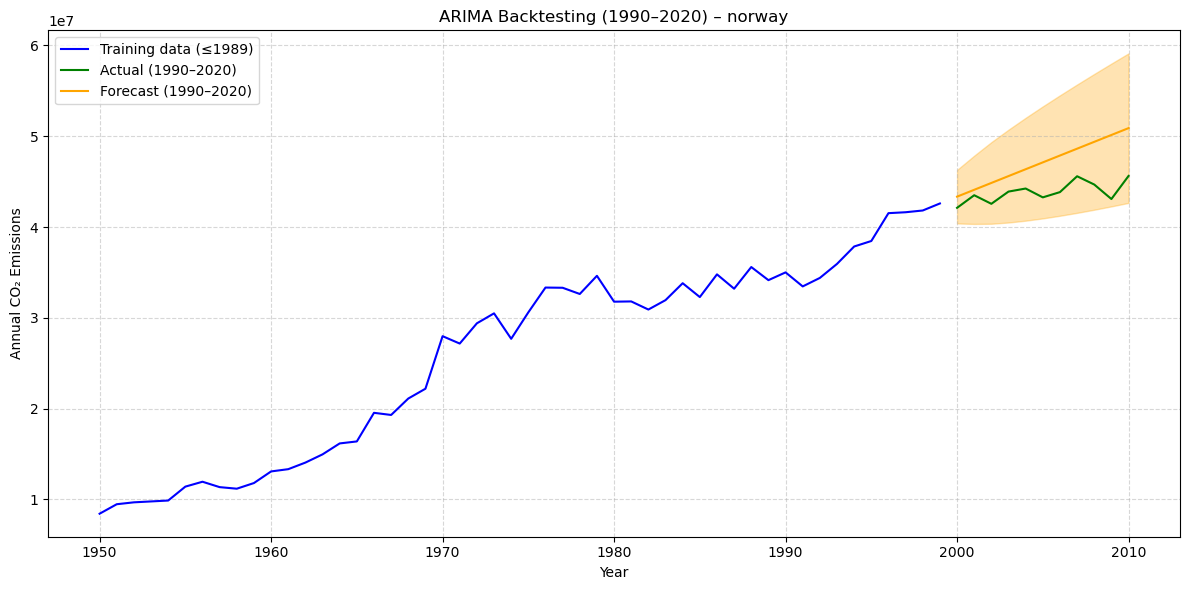

china | MAE: 1908656421.99, RMSE: 2390344351.56


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


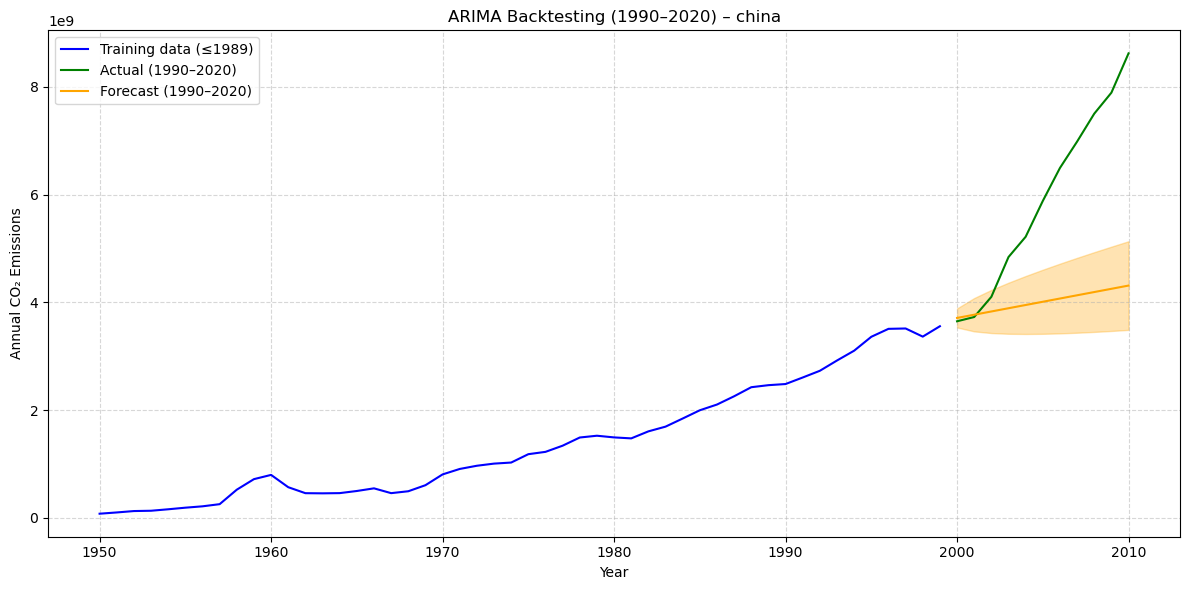

germany | MAE: 209624385.27, RMSE: 237583941.72


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


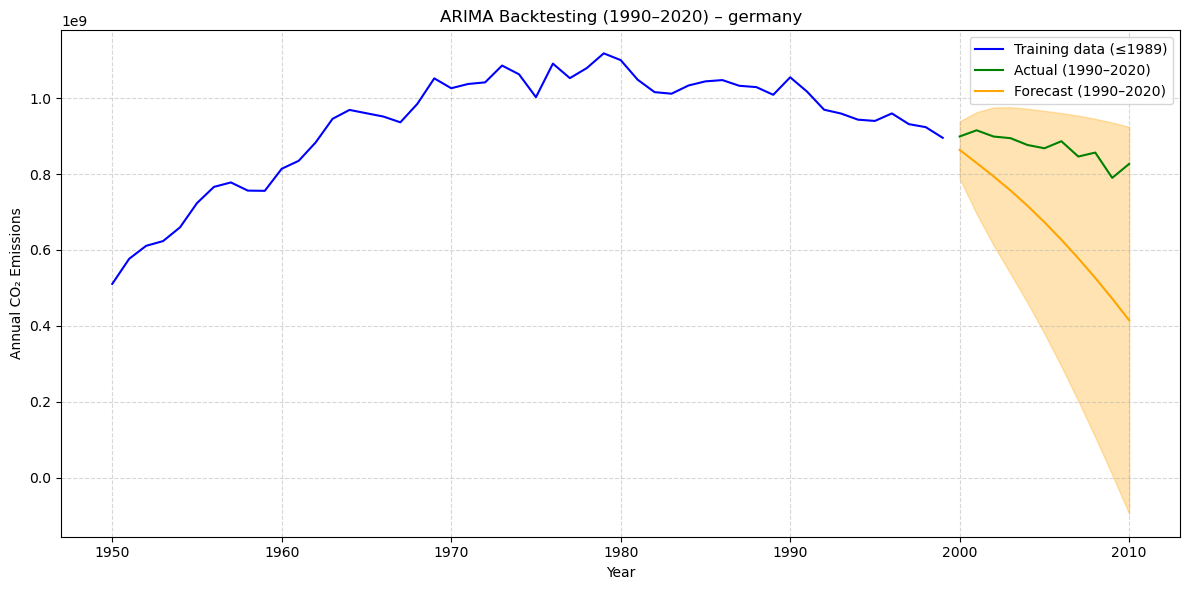

united states | MAE: 285375898.89, RMSE: 434088765.05


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


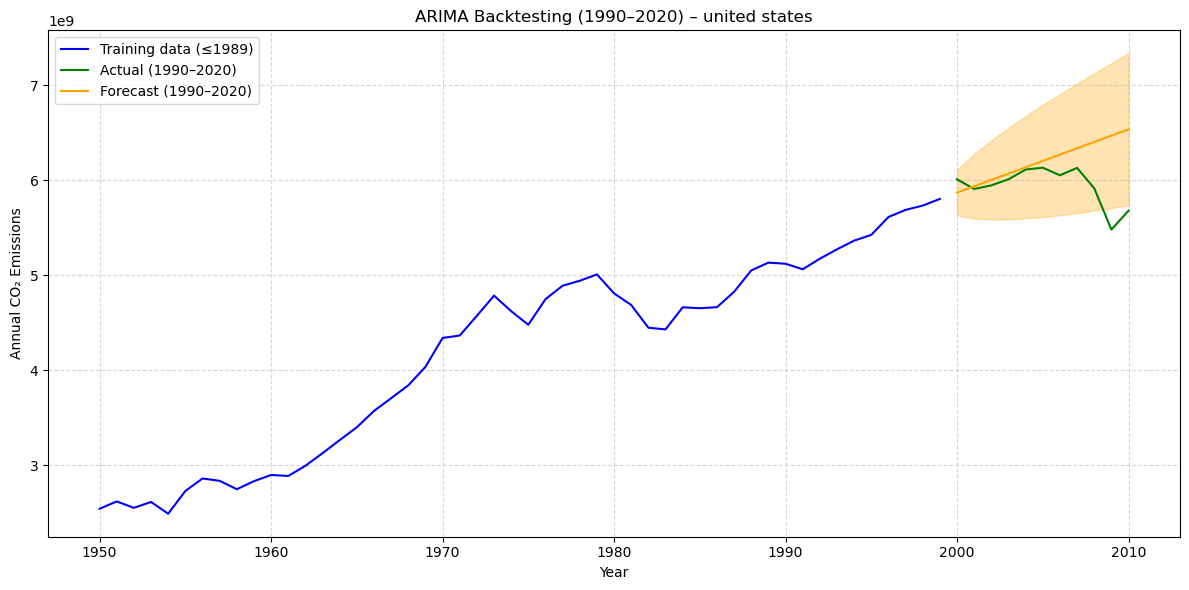

c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


france | MAE: 12630612.82, RMSE: 18589671.97


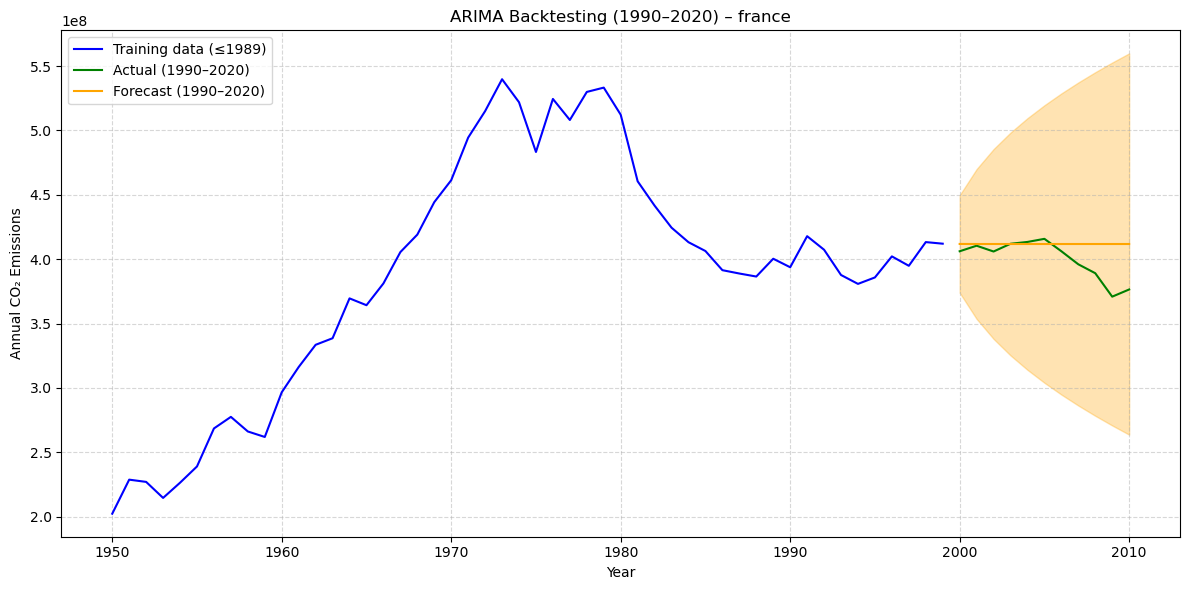

brazil | MAE: 10167119.92, RMSE: 16834875.86


c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\kambl\anaconda3\envs\Data_Analysis\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


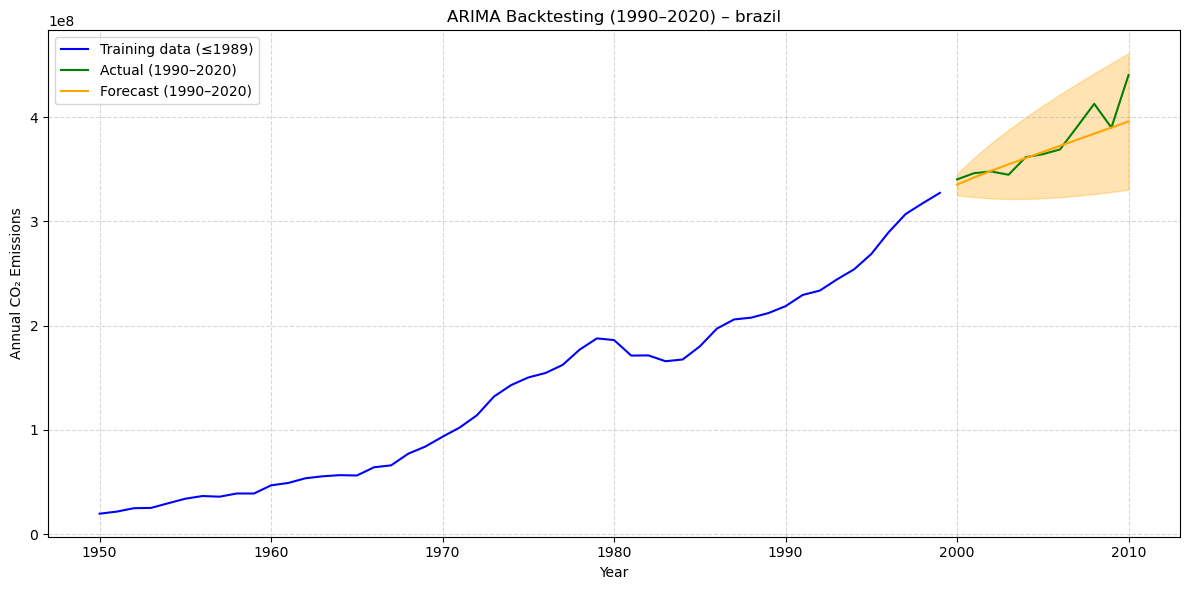

In [28]:
import pmdarima as pm
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

countries = df_total['Countries'].unique()

for country in countries:
    subset = df_total[df_total['Countries'] == country].sort_values('year')
    series = subset.set_index('year')['annual CO2'].dropna()

    # -------------------------------
    # Train-test split
    # -------------------------------
    train = series[(series.index >= 1950) & (series.index <= 1999)]
    test = series[(series.index >= 2000) & (series.index <= 2010)]

    if len(train) < 10 or len(test) < 5:
        print(f"⚠️ Not enough data for {country}")
        continue

    # -------------------------------
    # Fit ARIMA on training data
    # -------------------------------
    model = pm.auto_arima(
        train,
        seasonal=False,
        stepwise=True,
        suppress_warnings=True
    )

    # -------------------------------
    # Forecast for test period
    # -------------------------------
    n_periods = len(test)
    forecast, conf_int = model.predict(
        n_periods=n_periods,
        return_conf_int=True
    )

    forecast_index = test.index

    # -------------------------------
    # Error metrics (for report!)
    # -------------------------------
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    print(f"{country} | MAE: {mae:.2f}, RMSE: {rmse:.2f}")

    # -------------------------------
    # Plot comparison
    # -------------------------------
    plt.figure(figsize=(12, 6))
    plt.plot(train.index, train, label='Training data (≤1989)', color='blue')
    plt.plot(test.index, test, label='Actual (1990–2020)', color='green')
    plt.plot(forecast_index, forecast, label='Forecast (1990–2020)', color='orange')

    plt.fill_between(
        forecast_index,
        conf_int[:, 0],
        conf_int[:, 1],
        color='orange',
        alpha=0.3
    )

    plt.title(f'ARIMA Backtesting (1990–2020) – {country}')
    plt.xlabel('Year')
    plt.ylabel('Annual CO₂ Emissions')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


In [ ]:
import pmdarima as pm
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

countries = df_total['Countries'].unique()
forecast_results = []

for country in countries:
    subset = df_total[df_total['Countries'] == country].sort_values('year')
    series = subset.set_index('year')['annual CO2'].dropna()

    # Train-test split
    train = series[(series.index >= 1950) & (series.index <= 1999)]
    test = series[(series.index >= 2000) & (series.index <= 2010)]

    if len(train) < 10 or len(test) < 5:
        print(f"⚠️ Not enough data for {country}")
        continue

    # Fit ARIMA on training data
    model = pm.auto_arima(
        train,
        seasonal=False,
        stepwise=True,
        suppress_warnings=True
    )

    # Forecast for test period
    n_periods = len(test)
    forecast, conf_int = model.predict(
        n_periods=n_periods,
        return_conf_int=True
    )

    forecast_index = test.index

    # Store forecast results
    for year, pred_value, actual_value, lower_ci, upper_ci in zip(
        forecast_index, forecast, test.values, conf_int[:, 0], conf_int[:, 1]
    ):
        forecast_results.append({
            'Country': country,
            'Year': int(year),
            'Forecast': round(pred_value, 2),
            'Actual': round(actual_value, 2),
            'Lower_CI': round(lower_ci, 2),
            'Upper_CI': round(upper_ci, 2)
        })

    # Error metrics
    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    print(f"{country} | MAE: {mae:.2f}, RMSE: {rmse:.2f}")

    # Plot comparison
    import matplotlib.pyplot as plt
    plt.figure(figsize=(12, 6))
    plt.plot(train.index, train, label='Training data (1950-1999)', color='blue')
    plt.plot(test.index, test, label='Actual (2000-2010)', color='green')
    plt.plot(forecast_index, forecast, label='Forecast (2000-2010)', color='orange')

    plt.fill_between(
        forecast_index,
        conf_int[:, 0],
        conf_int[:, 1],
        color='orange',
        alpha=0.3
    )

    plt.title(f'ARIMA Backtesting (1950-1999 Train, 2000-2010 Test) – {country}')
    plt.xlabel('Year')
    plt.ylabel('Annual CO₂ Emissions')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Create DataFrame from forecast results
forecast_df = pd.DataFrame(forecast_results)

# Export to CSV
forecast_df.to_csv('forecast_results_2000_2010.csv', index=False)
print("\n✓ Forecast data exported to: forecast_results_2000_2010.csv")

# Export to Excel
forecast_df.to_excel('forecast_results_2000_2010.xlsx', index=False)
print("✓ Forecast data exported to: forecast_results_2000_2010.xlsx")

# Display the data
print("\nForecast Results Summary:")
print(forecast_df)